In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [2]:
orders = pd.read_csv('../data/processed/orders_features.csv', parse_dates=['order_purchase_timestamp'])
customers = pd.read_csv('../data/processed/customers_clean.csv', dtype={'customer_zip_code_prefix': str})
order_items = pd.read_csv('../data/processed/order_items_clean.csv')
products = pd.read_csv('../data/processed/products_clean.csv')

# Bring in customer state and main product category per order
orders = orders.merge(customers[['customer_id', 'customer_state']], on='customer_id', how='left')

main_category = order_items.merge(products[['product_id', 'product_category_name_english']], on='product_id') \
    .groupby('order_id')['product_category_name_english'].first().reset_index()
orders = orders.merge(main_category, on='order_id', how='left')

features = ['customer_state', 'product_category_name_english', 'order_value',
            'num_items', 'freight_value', 'order_month']
target = 'is_late'

data = orders[features + [target]].dropna()
data.shape

(96470, 7)

In [3]:
X = data[features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

y_train.value_counts(normalize=True)

is_late
0    0.932272
1    0.067728
Name: proportion, dtype: float64

In [4]:
categorical_features = ['customer_state', 'product_category_name_english', 'order_month']
numeric_features = ['order_value', 'num_items', 'freight_value']

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('num', StandardScaler(), numeric_features)
])

log_reg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

In [5]:
log_reg_pipeline.fit(X_train, y_train)
y_pred_lr = log_reg_pipeline.predict(X_test)

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.96      0.64      0.77     17987
           1       0.12      0.66      0.20      1307

    accuracy                           0.64     19294
   macro avg       0.54      0.65      0.49     19294
weighted avg       0.91      0.64      0.73     19294



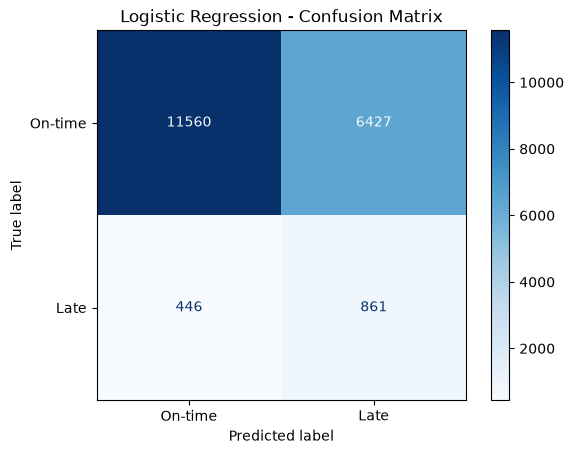

In [6]:
cm = confusion_matrix(y_test, y_pred_lr)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['On-time', 'Late'])
disp.plot(cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [7]:
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42))
])

tree_pipeline.fit(X_train, y_train)
y_pred_tree = tree_pipeline.predict(X_test)

print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

           0       0.96      0.79      0.87     17987
           1       0.15      0.50      0.23      1307

    accuracy                           0.77     19294
   macro avg       0.55      0.65      0.55     19294
weighted avg       0.90      0.77      0.82     19294



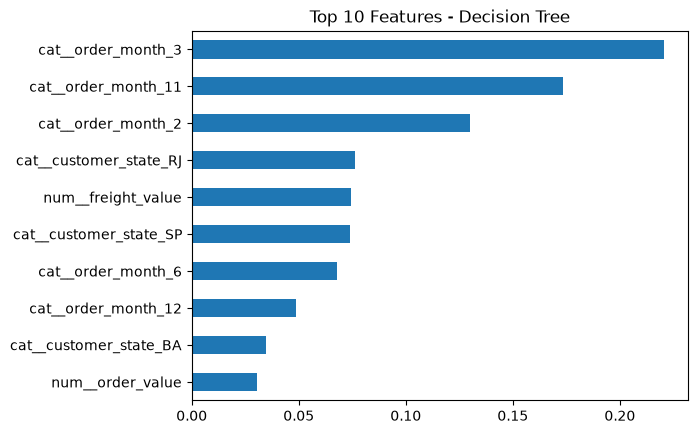

In [8]:
importances = tree_pipeline.named_steps['classifier'].feature_importances_
feature_names = tree_pipeline.named_steps['preprocessor'].get_feature_names_out()

feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(10)
feat_imp.plot(kind='barh')
plt.title('Top 10 Features - Decision Tree')
plt.gca().invert_yaxis()
plt.show()

In [9]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)

print("=" * 60)
print("RANDOM FOREST RESULTS")
print("=" * 60)
print(classification_report(y_test, y_pred_rf))

RANDOM FOREST RESULTS
              precision    recall  f1-score   support

           0       0.96      0.74      0.84     17987
           1       0.15      0.60      0.23      1307

    accuracy                           0.73     19294
   macro avg       0.55      0.67      0.54     19294
weighted avg       0.91      0.73      0.80     19294



In [10]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [8, 12, None]
}

grid = GridSearchCV(rf_pipeline, param_grid, scoring='recall', cv=3)
grid.fit(X_train, y_train)
print(grid.best_params_)

{'classifier__max_depth': 8, 'classifier__n_estimators': 100}
